# Pandas로 표 다루기

**이 노트북에서 할 일**

1. 주문 세 건을 CSV 파일로 저장하고, pandas로 읽어 행·열·자료형을 확인합니다.
2. 상태 열의 조건으로 결제 완료 주문만 고르고, 같은 일을 하는 조회 함수를 만듭니다.
3. 금액 열을 글자로 읽었을 때 합계가 틀리는 장면을 보고, 숫자로 바꿔 고칩니다.

**준비물** — API 키 불필요. 주문 파일은 노트북이 임시 폴더에 직접 만듭니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

**기준 pandas 버전** — 실습 폴더에 고정한 pandas 3.0.5를 씁니다. 교재 출력도 이 버전(Python 3.12.13)으로 만들었습니다.
이 버전은 Python 3.11 이상에서 설치됩니다. pandas 2 이하에서는 자료형 이름 같은 출력 모양이 다를 수 있고, 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch04-data-tools`에서 Ch 1 3절처럼 `uv sync --locked`로 환경을 만듭니다.
커널에서 이 폴더의 `.venv`를 고른 뒤 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

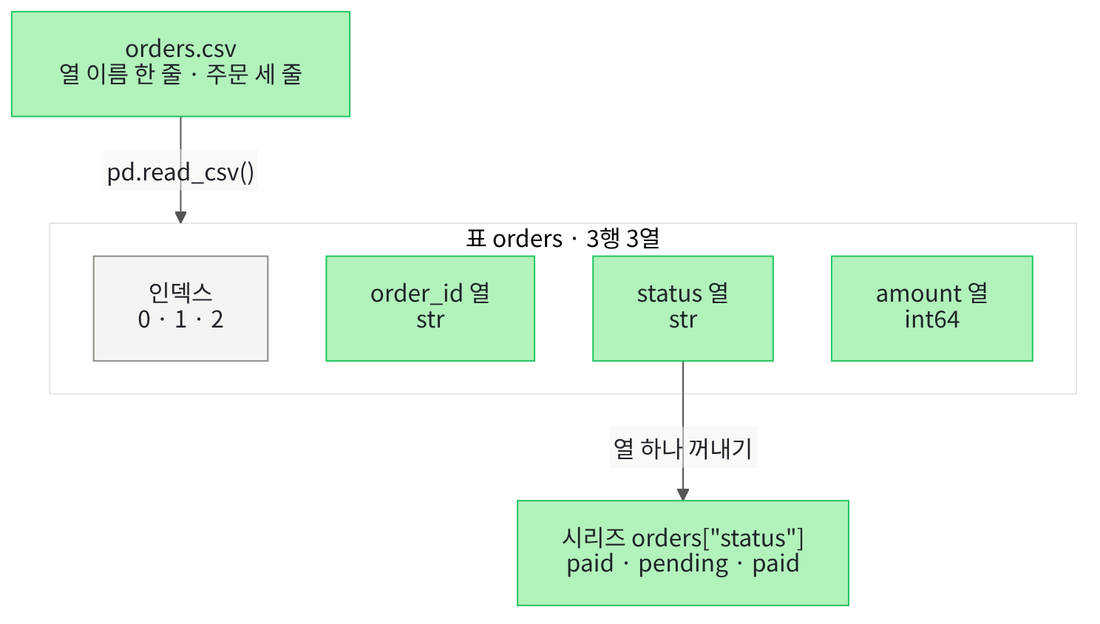

위에서 아래로 읽습니다. 초록 상자는 파일과 표의 열처럼 값이 담긴 자리이고, 화살표 옆 글자는 실행한 코드나 한 일입니다.
가운데 칸의 회색 상자는 pandas가 붙인 행 번호(인덱스)입니다. 맨 아래 상자가 상태 열 하나를 꺼낸 시리즈입니다.

## 1. 준비

이 노트북은 주문 파일 하나를 만듭니다. Ch 2 08절과 Ch 3처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
실습 폴더에는 파일이 생기지 않습니다.

코드의 import 두 줄은 Ch 2 07절에서 배운 import 문입니다. 표준 라이브러리 모듈 os와 tempfile을 불러옵니다.

In [1]:
# 주문 파일을 둘 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch04-01-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.
폴더의 경로는 컴퓨터마다 달라서 출력하지 않았습니다.

## 2. pandas 불러오기

표 데이터를 다루는 패키지 pandas를 불러옵니다. 패키지는 Ch 1 3절에서 본 「따로 설치하는 기능 묶음」입니다.
실습 폴더에서 실행한 `uv sync --locked`가 이미 설치해 두었습니다.

이번 import 줄 끝에는 `as pd`가 붙습니다. 키워드 `as`는 불러온 모듈에 짧은 별명을 붙입니다.
그래서 뒤의 셀은 `pandas.read_csv()` 대신 `pd.read_csv()`로 씁니다. 별명 pd는 pandas 설명서와 많은 코드가 함께 쓰는 관례입니다.

모듈 안의 이름 `__version__`에는 설치된 버전 글자가 들어 있습니다. Ch 2 07절의 `__name__`처럼 밑줄 두 개로 감싼 이름입니다.
실행 전에 예상합니다. 실습 폴더에 고정한 버전 3.0.5가 출력될 것입니다.

In [2]:
# 표 데이터를 다루는 pandas를 별명 pd로 불러옵니다
import pandas as pd

# 설치된 pandas 버전을 출력합니다
print("pandas 버전:", pd.__version__)

pandas 버전: 3.0.5


**결과 읽기** — `pandas 버전: 3.0.5`로 예상과 같습니다.
다른 버전이 나오면 커널이 실습 폴더의 `.venv`인지 확인합니다.

## 3. 주문 파일 만들기

주문 세 건을 CSV 파일로 저장합니다. CSV(comma-separated values)는 한 줄에 값을 쉼표로 나눠 적은 글 파일입니다.
Ch 2 05절의 `orders.txt`에 「연필,3」처럼 적은 모양과 같습니다.

다른 점은 첫 줄입니다. CSV 파일의 첫 줄에는 보통 값 대신 열 이름을 적습니다.
이번 파일의 열 이름은 주문 번호 `order_id`, 상태 `status`, 금액 `amount`입니다.

상태 값 `paid`는 결제 완료, `pending`은 결제 대기라는 뜻입니다. 금액은 Ch 2 02절부터 쓴 원 단위 정수입니다.
파일은 Ch 2 05절처럼 `with open()` 블록과 여러 줄 글 `"""…"""`로 저장합니다.

실행 전에 예상합니다. 폴더 목록에 `orders.csv` 하나가 보일 것입니다.

In [3]:
# 주문 세 건을 CSV 글로 적어 orders.csv 파일에 저장합니다
order_text = """order_id,status,amount
O101,paid,32000
O102,pending,18000
O103,paid,27000
"""
with open("orders.csv", "w", encoding="utf-8") as file:
    file.write(order_text)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: ['orders.csv']


**결과 읽기** — 현재 작업 폴더의 파일은 `['orders.csv']`로 예상과 같습니다.
이 파일은 열 이름 한 줄과 주문 세 줄, 모두 네 줄입니다.

## 4. 파일을 표로 읽기

함수 `pd.read_csv()`는 CSV 파일 이름을 받아 표 하나를 반환합니다. 첫 줄은 열 이름으로, 다음 줄부터는 행으로 읽습니다.
이렇게 만든 표를 데이터프레임(DataFrame)이라고 부릅니다.

Ch 2 05절에서는 줄마다 `split(",")`로 값을 나누고 `int()`로 수량을 숫자로 바꿨습니다.
함수 `pd.read_csv()`는 파일 전체를 한 번에 읽고, 숫자로 보이는 열은 숫자로 읽습니다.

실행 전에 예상합니다. 열 이름 한 줄 아래에 주문 세 건이 한 줄씩 출력될 것입니다.

In [4]:
# CSV 파일을 읽어 표(DataFrame) 하나를 만듭니다
orders = pd.read_csv("orders.csv")
print("주문 표:")
print(orders)

주문 표:
  order_id   status  amount
0     O101     paid   32000
1     O102  pending   18000
2     O103     paid   27000


**결과 읽기** — 라벨 줄 아래 첫 줄은 열 이름 `order_id`, `status`, `amount`입니다. 그 아래 세 줄이 주문 한 건씩입니다.
한 주문이 가로 한 줄인 행(row)이고, 주문 번호·상태·금액이 세로 한 줄씩인 열(column)입니다.

줄 맨 앞의 `0`, `1`, `2`는 파일에 없던 번호입니다. 표가 행마다 붙인 이 번호를 인덱스(index)라고 부릅니다.
Ch 2 02절의 위치 번호처럼 0부터 셉니다. 주문 번호 `O101`과는 다른 값입니다.

표의 크기와, 열마다 담긴 값의 종류를 확인합니다. 속성 `shape`에는 (행 수, 열 수)가 튜플로 들어 있습니다.
튜플은 Ch 2 03절에서 배웠습니다.

속성 `dtypes`는 열마다 자료형(dtype)을 보여 줍니다. 자료형은 Ch 2 01절의 int와 str처럼 값의 종류입니다.
표의 열 하나에는 같은 자료형의 값이 들어갑니다.

실행 전에 예상합니다. 3행 3열이고, 금액 열만 정수 자료형일 것입니다.

In [5]:
# 표의 크기(행 수, 열 수)와 열마다의 자료형을 확인합니다
print("행과 열의 수:", orders.shape)
print("열마다의 자료형:")
print(orders.dtypes)

행과 열의 수: (3, 3)
열마다의 자료형:
order_id      str
status        str
amount      int64
dtype: object


**결과 읽기** — `행과 열의 수: (3, 3)`은 3행 3열이라는 뜻입니다.
자료형 목록에서 금액 열은 `int64`입니다. Ch 2 01절의 int와 같은 정수이고, 64는 값 하나를 저장하는 크기(64비트)입니다.
주문 번호와 상태 열은 글자 열이라 `str`로 나왔습니다. 마지막 줄 `dtype: object`는 이 목록 자체에 붙은 표시라 지금은 읽지 않습니다.

## 5. 열 하나 꺼내고 조건과 비교하기

표 이름 뒤 대괄호에 열 이름을 넣으면 그 열 하나를 꺼냅니다. Ch 2 03절에서 딕셔너리의 키로 값을 읽던 모양과 같습니다.

꺼낸 열 하나를 시리즈(Series)라고 부릅니다. 시리즈는 인덱스와 값을 짝지어 한 줄로 담습니다.
번호가 붙은 목록이라고 생각하면 됩니다.

실행 전에 예상합니다. 인덱스 0, 1, 2 옆에 상태 값 세 개가 출력될 것입니다.

In [6]:
# 표에서 상태 열 하나를 꺼냅니다
status_column = orders["status"]
print("상태 열:")
print(status_column)

상태 열:
0       paid
1    pending
2       paid
Name: status, dtype: str


**결과 읽기** — 왼쪽 `0`, `1`, `2`는 표의 인덱스이고, 오른쪽이 상태 값 `paid`, `pending`, `paid`입니다.
마지막 줄 `Name: status, dtype: str`은 이 시리즈의 열 이름과 자료형을 알려 줍니다.

꺼낸 열을 글자 `"paid"`와 연산자 `==`로 비교합니다. Ch 2 02절에서는 값 하나를 비교해 `True`나 `False` 하나를 얻었습니다.
시리즈를 비교하면 행마다 따로 비교해, 참·거짓이 담긴 시리즈 하나를 만듭니다.

행마다 고를지 말지를 적은 이 참·거짓 시리즈를 불리언 마스크(boolean mask)라고 부릅니다.
불리언은 Ch 2 01절의 bool 자료형입니다.

실행 전에 예상합니다. 상태가 paid인 0번과 2번 행이 참일 것입니다.

In [7]:
# 상태 열을 "paid"와 비교해 행마다 참·거짓을 만듭니다
paid_mask = status_column == "paid"
print("paid와 같은가:")
print(paid_mask)

paid와 같은가:
0     True
1    False
2     True
Name: status, dtype: bool


**결과 읽기** — 0번과 2번 행이 `True`, 1번 행이 `False`로 예상과 같습니다.
마지막 줄의 자료형이 `dtype: bool`로 바뀌었습니다. 값이 참·거짓이기 때문입니다.

## 6. loc로 행 고르기

표 뒤에 `.loc[마스크]`를 붙이면 마스크가 `True`인 행만 남긴 새 표를 만듭니다.
이름 loc는 위치를 뜻하는 location에서 왔습니다. 인덱스 번호표로 행을 찾는다는 뜻입니다.

원래 표 `orders`는 바뀌지 않습니다. 고른 결과는 새 이름 `paid_orders`에 담습니다.
실행 전에 예상합니다. 주문 O101과 O103 두 줄만 남고, 원래 표는 그대로 3행일 것입니다.

In [8]:
# 마스크가 True인 행만 고른 새 표를 만듭니다
paid_orders = orders.loc[paid_mask]
print("결제 완료 주문 표:")
print(paid_orders)
# 원래 표의 행 수는 len()으로 셉니다
print("원래 표의 행 수:", len(orders))

결제 완료 주문 표:
  order_id status  amount
0     O101   paid   32000
2     O103   paid   27000
원래 표의 행 수: 3


**결과 읽기** — `O101`과 `O103` 두 줄만 남았습니다. 인덱스는 `0`과 `2`로, 원래 표의 번호를 그대로 가집니다.
마지막 줄 `원래 표의 행 수: 3`으로 원래 표가 바뀌지 않았음을 확인합니다.

대괄호 안에 쉼표를 두고 열 이름을 더 적으면, 고른 행에서 그 열만 꺼냅니다. 모양은 `표.loc[행 조건, 열 이름]`입니다.

꺼낸 금액 시리즈에 메서드 `sum()`을 붙이면 값을 모두 더합니다.
실행 전에 예상합니다. 결제 완료 주문의 금액은 32000과 27000이므로, 합계는 59000일 것입니다.

In [9]:
# 결제 완료 행의 금액 열만 꺼내 합계를 냅니다
paid_amounts = orders.loc[paid_mask, "amount"]
print("결제 완료 금액:")
print(paid_amounts)
paid_total = paid_amounts.sum()
print("결제 완료 합계:", paid_total)

결제 완료 금액:
0    32000
2    27000
Name: amount, dtype: int64
결제 완료 합계: 59000


**결과 읽기** — 금액 시리즈에는 `32000`과 `27000`이 인덱스 0, 2와 함께 남았습니다.
마지막 줄은 `결제 완료 합계: 59000`으로 예상과 같습니다.

## 7. 조회 함수 만들기

같은 조회를 상태만 바꿔 여러 번 하려고 함수로 묶습니다. Ch 2 04절처럼 정의 셀과 호출 셀을 나눕니다.
이 함수는 파일 이름과 상태를 받아, 그 상태의 주문 목록을 반환합니다.

반환값은 표가 아니라 딕셔너리의 목록입니다. 메서드 `to_dict(orient="records")`는 행 하나를 딕셔너리 하나로 바꾼 목록을 만듭니다.
딕셔너리의 키는 열 이름입니다. Ch 2 03절의 주문 딕셔너리 `order`와 같은 모양이라, pandas를 모르는 코드도 결과를 쓸 수 있습니다.

정의 줄의 `-> list`는 목록을 반환한다는 표시입니다. Ch 2 07절에서 배운 `-> int`와 같은 타입힌트 모양입니다.
실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [10]:
# 파일 이름과 상태를 받아, 그 상태의 주문을 딕셔너리 목록으로 반환하는 함수
def fetch_orders(file_name: str, status: str) -> list:
    table = pd.read_csv(file_name)
    # 상태 열이 status와 같은 행만 True인 마스크를 만듭니다
    status_mask = table["status"] == status
    selected = table.loc[status_mask]
    # 행 하나를 딕셔너리 하나로 바꾼 목록을 만듭니다
    records = selected.to_dict(orient="records")
    return records

**결과 읽기** — 예상대로 출력이 없습니다. 함수를 만들기만 했습니다.

상태 `"paid"`로 함수를 호출합니다. 주문 번호만 모아 목록으로 만들고 `assert`로 확인합니다.
번호 모으기는 Ch 2 03절에서 배운 빈 목록과 `for`, `append()` 모양입니다.

실행 전에 예상합니다. 딕셔너리 두 개가 나오고, 주문 번호 목록은 O101과 O103일 것입니다.

In [11]:
# 결제 완료 주문을 조회하고, 주문 번호만 모아 확인합니다
paid_records = fetch_orders("orders.csv", "paid")
print("조회 결과:", paid_records)
paid_ids = []
for record in paid_records:
    paid_ids.append(record["order_id"])
print("주문 번호:", paid_ids)
assert paid_ids == ["O101", "O103"]

조회 결과: [{'order_id': 'O101', 'status': 'paid', 'amount': 32000}, {'order_id': 'O103', 'status': 'paid', 'amount': 27000}]
주문 번호: ['O101', 'O103']


**결과 읽기** — 조회 결과의 첫 딕셔너리는 `{'order_id': 'O101', 'status': 'paid', 'amount': 32000}`입니다.
인덱스 번호는 사라지고, 열 이름이 딕셔너리의 키가 되었습니다.
주문 번호 목록은 `['O101', 'O103']`이고, `assert` 줄도 멈추지 않았습니다.

## 8. 값 하나 바꿔 보기 — paid를 pending으로

함수와 파일은 그대로 두고, 상태 인자 하나만 `"paid"`에서 `"pending"`으로 바꿉니다.
실행 전에 예상합니다. 결제 대기 주문은 O102 하나이므로 딕셔너리 하나만 나올 것입니다.

In [12]:
# 상태 인자만 "pending"으로 바꿔 같은 함수를 호출합니다
pending_records = fetch_orders("orders.csv", "pending")
print("조회 결과:", pending_records)
print("주문 수:", len(pending_records))
assert len(pending_records) == 1

조회 결과: [{'order_id': 'O102', 'status': 'pending', 'amount': 18000}]
주문 수: 1


**결과 읽기** — 조회 결과는 `{'order_id': 'O102', 'status': 'pending', 'amount': 18000}` 하나입니다.
마지막 줄은 `주문 수: 1`로 예상과 같습니다. 인자 하나만 바꿔 다른 주문을 골랐습니다.

## 9. Before — 모든 열을 글자로 읽고 금액 합계 내기

주문 번호처럼 계산하지 않는 값을 글자로 지키려고, 파일의 모든 열을 글자로 읽었다고 해 봅니다.
앞자리 0이 있는 번호(예: `01234`)는 숫자로 읽히면 0이 사라지기 때문입니다. 이번 파일에는 그런 번호가 없어 실행하지 않았습니다.
함수 `pd.read_csv()`에 인자 `dtype=str`을 주면 모든 열을 글자로 읽습니다.
Ch 2 05절에서 파일에서 읽은 줄이 모두 글자였던 것과 같은 상태입니다.

실행 전에 예상합니다. 표는 앞과 같아 보이지만, 자료형 목록에서 금액 열도 `str`로 바뀔 것입니다.

In [13]:
# Before: 모든 열을 글자로 읽고, 표와 자료형을 확인합니다
text_orders = pd.read_csv("orders.csv", dtype=str)
print("글자로 읽은 표:")
print(text_orders)
print("열마다의 자료형:")
print(text_orders.dtypes)

글자로 읽은 표:
  order_id   status amount
0     O101     paid  32000
1     O102  pending  18000
2     O103     paid  27000
열마다의 자료형:
order_id    str
status      str
amount      str
dtype: object


**결과 읽기** — 표의 금액은 앞의 표처럼 `32000`, `18000`, `27000`으로 보입니다.
하지만 자료형 목록에서는 세 열 모두 `str`입니다. 금액 열의 값이 숫자가 아니라 글자라는 뜻입니다.

이 금액 열로 합계를 냅니다. 합계 값의 자료형도 Ch 2 01절의 `type()`으로 함께 봅니다.
실행 전에 예상합니다. 숫자라면 32000 + 18000 + 27000 = 77000이어야 합니다.

In [14]:
# Before: 글자 금액 열로 합계를 내고, 합계의 자료형을 봅니다
wrong_total = text_orders["amount"].sum()
print("금액 합계:", wrong_total)
print("합계의 자료형:", type(wrong_total))

금액 합계: 320001800027000
합계의 자료형: <class 'str'>


**결과 읽기** — 예상과 달리 `금액 합계: 320001800027000`이 나왔습니다. 세 금액 글자를 차례로 이어 붙인 값입니다.
합계의 자료형도 `<class 'str'>`로 글자입니다. Ch 3 01절에서 글자 사이의 `+`가 두 글을 이어 붙였던 것과 같습니다.

셀은 오류 없이 끝났습니다. 출력의 자릿수를 보지 않으면 틀린 줄 모르고 넘어갈 수 있습니다.

## 10. After — 금액 열을 숫자로 바꾸고 합계 내기

함수 `pd.to_numeric()`은 글자 시리즈를 받아 숫자 시리즈를 반환합니다.
Ch 2 05절의 `int()`가 글자 하나를 바꿨다면, 이 함수는 열 전체를 한 번에 바꿉니다.

바꾼 시리즈는 `text_orders["amount"] = …`처럼 같은 열 이름에 다시 대입합니다. 딕셔너리에 같은 키로 새 값을 넣던 Ch 2 03절 모양과 같습니다.
열의 자료형 하나는 시리즈의 속성 `dtype`으로 봅니다.

실행 전에 예상합니다. 금액 열의 자료형이 `int64`로 바뀌고, 합계는 77000일 것입니다.

In [15]:
# After: 금액 열을 숫자로 바꿔 같은 열에 다시 넣고 합계를 냅니다
amount_numbers = pd.to_numeric(text_orders["amount"])
text_orders["amount"] = amount_numbers
print("금액 열의 자료형:", text_orders["amount"].dtype)
correct_total = text_orders["amount"].sum()
print("금액 합계:", correct_total)
assert correct_total == 77000

금액 열의 자료형: int64
금액 합계: 77000


**결과 읽기** — `금액 열의 자료형: int64`로 정수 열이 되었습니다.
합계는 `금액 합계: 77000`으로 예상과 같고, `assert` 줄도 멈추지 않았습니다.

금액 자리에 숫자가 아닌 글자가 섞여 있으면 어떻게 될까요? Ch 2 13절의 「연필,많이」 같은 줄입니다.
이번에는 두 번째 금액 자리에 「미정」이 들어간 목록으로 확인합니다. 함수 `pd.to_numeric()`은 시리즈 대신 목록도 받습니다.

오류가 나도 셀이 끝까지 실행되도록, Ch 2 05절처럼 오류 이름 ValueError만 받는 `try/except`로 감쌉니다.
실행 전에 예상합니다. 「미정」을 숫자로 읽을 수 없다는 오류 메시지가 출력될 것입니다.

In [16]:
# After: 숫자로 바꿀 수 없는 금액이 섞이면 어떤 오류가 나는지 봅니다
amount_texts = ["32000", "미정", "27000"]
try:
    pd.to_numeric(amount_texts)
except ValueError as error:
    print("변환 오류:", error)

변환 오류: Unable to parse string "미정" at position 1


**결과 읽기** — `변환 오류: Unable to parse string "미정" at position 1`이 나왔습니다.
끝의 `position 1`은 0부터 센 위치 번호라 두 번째 값을 가리킵니다.
함수는 숫자로 바꿀 수 없는 값을 만나면 멈추고 오류로 알립니다. 그래서 틀린 합계를 내기 전에 문제 값을 찾을 수 있습니다.

## 정리

- 함수 `pd.read_csv()`는 CSV 파일을 표(DataFrame)로 읽습니다. 속성 `dtypes`로 열마다 자료형을 먼저 확인합니다.
- 열 하나(Series)를 조건과 비교해 마스크를 만들고, `표.loc[마스크]`로 필요한 행만 고릅니다.
- 글자 금액 열의 `sum()`은 글자를 이어 붙입니다. 합계 전에 `pd.to_numeric()`으로 숫자로 바꿉니다.

이번에는 Linux의 pandas 3.0.5로 실행했습니다. 다른 운영체제에서는 실행하지 않았습니다.
다음 절에서는 주문 표에 고객 번호 열을 더해, 고객 표와 연결합니다.